# Probabilistic FDM — Poisson方程式 (Matérnカーネル)

PDE: $-u''(x) = f(x) = \sin(2\pi x)$, $\quad u(0)=u(18)=0$

真の解: $u(x) = \frac{1}{(2\pi)^2}\sin(2\pi x)$

観測モデル: $y = H u + \varepsilon$, $\quad H = -\Delta_h$

観測ノイズ:
\[
\varepsilon \sim \mathcal{N}(0,\, C h^{2\tau} I_{M,N}).
\]

この版では

- $\tau=2$ を固定
- $\sigma_f$ は標準FDM解の RMS から固定
- $C$ は target-grid の標準FDM解 $u_h$ に $2h$ stencil を適用した coarsening defect から推定
- $\ell$ のみ log marginal likelihood でグリッドサーチ

とする。追加の $h/2$ solve は不要。


In [12]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Printf
using Statistics

In [13]:
function solve_fdm(dt)
    x_all = collect(0.0:dt:18.0)
    x_int = x_all[2:end-1]
    n_int = length(x_int)
    A = SymTridiagonal(fill(2.0/dt^2, n_int), fill(-1.0/dt^2, n_int-1))
    f_vec = f_func.(x_int)
    u_int = ldiv!(factorize(A), copy(f_vec))
    return x_all, vcat(0.0, u_int, 0.0)
end

dt = 0.4
x_fdm, u_fdm = solve_fdm(dt)
err = maximum(abs.(u_fdm .- u_exact.(x_fdm)))
println("h=$(dt):  max|u_fdm - u_exact| = $(round(err, sigdigits=4))")



σf_rms  = sqrt(mean(u_fdm.^2))
σf_max = maximum(abs.(u_fdm))

println(σf_rms)
println(σf_max)

# --------------------------------------------------------
# C の coarsening-based calibration
#
# truncation error:
#     D_h u - f = c(x) h^p + higher-order terms
#
# target-grid FDM solution u_h を一段粗い 2h stencil で検査すると
#     D_{2h} u_h - f ≈ (2^p - 1) c(x) h^p
#
# よって
#     c_hat(x) = [D_{2h} u_h - f] / [(2^p - 1) h^p]
#     C_hat    = mean(c_hat(x)^2)
#
# 注意:
# [0,18] と h=0.4 のように interval 数が奇数でも使えるよう、
# 完全な 2h-grid は作らず、u_h 上で ±2 index が存在する
# every-other interior point のみを使用する。
# --------------------------------------------------------
function estimate_C_coarsening(dt; p=2)
    x_h, u_h = solve_fdm(dt)
    n = length(x_h)

    # Julia index i corresponds to x_h[i].
    # Use centers i = 3,5,7,... such that i-2 and i+2 both exist.
    idx = collect(3:2:(n-2))
    if isempty(idx)
        error("Grid is too coarse to estimate C using a 2h stencil.")
    end

    h2 = 2dt
    defect = similar(Float64.(idx))

    for (k, i) in enumerate(idx)
        D2h_u = (-u_h[i-2] + 2u_h[i] - u_h[i+2]) / h2^2
        defect[k] = D2h_u - f_func(x_h[i])
    end

    c_hat = defect ./ ((2.0^p - 1.0) * dt^p)
    C_hat = mean(c_hat .^ 2)

    return C_hat, x_h[idx], c_hat, defect
end


h=0.4:  max|u_fdm - u_exact| = 0.01797
0.030928558807569867
0.04205848896953482


estimate_C_coarsening (generic function with 1 method)

## 1. Matérnカーネル

In [14]:
function matern_kernel(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    if r == 0
        return σf^2
    end
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_matern(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ, σf=σf) for x1 in X1, x2 in X2]
end

kernel_matrix_matern (generic function with 1 method)

## 2. 問題設定・観測行列 H・log周辺尤度

In [15]:
# --------------------------------------------------------
# 問題設定: -u'' = f, u(0)=u(1)=0
# f(x) = sin(2πx), u_exact(x) = sin(2πx)/(2π)^2
# --------------------------------------------------------
u_exact(x) = sin(2π * x) / (2π)^2
f_func(x)  = sin(2π * x)

# --------------------------------------------------------
# 観測行列 H = -Δ_h (負の有限差分ラプラシアン)
# 行順: [bdry_0, int_1, ..., int_{N-1}, bdry_N]
# 内点行: (-u_{i-1} + 2u_i - u_{i+1}) / h^2  = -Δ_h u_i ≈ -u''_i = f_i
# → Hu = y = (0, f(x_1), ..., f(x_{N-1}), 0) と直接対応
# --------------------------------------------------------
function observation_matrix(n_total, dt)
    n_int = n_total - 2
    H = zeros(n_total, n_total)
    H[1, 1]     = 1.0
    H[end, end] = 1.0
    for i in 1:n_int
        H[i+1, i]   = -1.0 / dt^2   # -Δ_h
        H[i+1, i+1] =  2.0 / dt^2
        H[i+1, i+2] = -1.0 / dt^2
    end
    return H
end

# 観測ベクトル: y = (u(0), f(x_1), ..., f(x_{N-1}), u(1))
make_y_train(x_all) = vcat(0.0, f_func.(x_all[2:end-1]), 0.0)

# --------------------------------------------------------
# log周辺尤度: 観測ノイズ Σ = C * h^{2τ} * diag(0,1,...,1,0)
# --------------------------------------------------------
function log_marginal_matern(
    X_train, y; H, dt, ν, ℓ, σf, C, τ, jitter=1e-10
)
    n_total   = length(X_train)
    noise_var = C * dt^(2τ)
    Σ_diag    = vcat([0.0], fill(noise_var, n_total - 2), [0.0])
    Σ         = Diagonal(Σ_diag)

    K     = kernel_matrix_matern(X_train, X_train; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ #+ jitter * I

    L       = cholesky(Hermitian(K_obs)).L
    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))

    return -0.5 * (y' * α) - 0.5 * logdetK - 0.5 * length(y) * log(2π)
end

log_marginal_matern (generic function with 1 method)

## 3. ハイパーパラメータ選択（$C$ は defect calibration、$\ell$ のみグリッドサーチ）

In [16]:
ν_fixed = 1.5
τ_fixed = 2

# 必要に応じて増やす
dt_list = [0.4]

# ℓ のみグリッドサーチ
#ℓ_grid = 10.0 .^ range(-2, 2, length=20)
#ℓ_grid = [0.4, 0.5, 1.0, 2.0]
ell_factors = [0.5, 0.75, 1.0, 1.5, 2.0]
ℓ_grid = dt*ell_factors 

best_params = Dict()

for dt in dt_list
    x_all   = collect(0.0:dt:18.0)
    n_total = length(x_all)
    H       = observation_matrix(n_total, dt)
    y_train = make_y_train(x_all)

    # ----------------------------------------------------
    # 1) 標準FDM解を利用して σf を固定
    # ----------------------------------------------------
    _, u_fdm = solve_fdm(dt)
    #σf_fixed = sqrt(mean(u_fdm .^ 2))
    σf_fixed =0.04

    # ----------------------------------------------------
    # 2) 同じ target-grid 解 u_h から C を calibration
    #    追加の h/2 solve は不要
    # ----------------------------------------------------
    C_hat, x_C, c_hat, defect = estimate_C_coarsening(dt; p=τ_fixed)

    # ----------------------------------------------------
    # 3) ℓ だけ log marginal likelihood で grid search
    # ----------------------------------------------------
    scores = fill(-Inf, length(ℓ_grid))

    for (i, ℓ) in enumerate(ℓ_grid)
        try
            scores[i] = log_marginal_matern(
                x_all, y_train;
                H=H, dt=dt, ν=ν_fixed,
                ℓ=ℓ, σf=σf_fixed, C=C_hat, τ=τ_fixed
            )
        catch err
            @warn "LML failed" dt ℓ exception=(err, catch_backtrace())
            scores[i] = -Inf
        end
    end

    best_idx = argmax(scores)
    best_ℓ   = ℓ_grid[best_idx]

    best_params[dt] = (best_ℓ, σf_fixed, C_hat)

    println("dt=$(dt):")
    println("  C_hat  = $(round(C_hat, sigdigits=6))  [coarsening calibration]")
    println("  σf     = $(round(σf_fixed, sigdigits=6))  [FDM RMS]")
    println("  best ℓ = $(round(best_ℓ, sigdigits=6))")
    println("  loglik = $(round(scores[best_idx], sigdigits=7))")
end


dt=0.4:
  C_hat  = 1.84387  [coarsening calibration]
  σf     = 0.04  [FDM RMS]
  best ℓ = 0.2
  loglik = -19.59856


## 4. 事後分布の計算と4パネル図


=== Fine test-grid evaluation ===
----------------------------------------
h              = 0.4
n_train        = 46
n_test         = 1801
ell            = 0.2
sigma_f        = 0.04
C_hat          = 1.84387
RMSE           = 0.00913881
Linf           = 0.0153167
coverage       = 1.000
mean 95% width = 0.0618881

Saved: poisson_matern_finetest.png


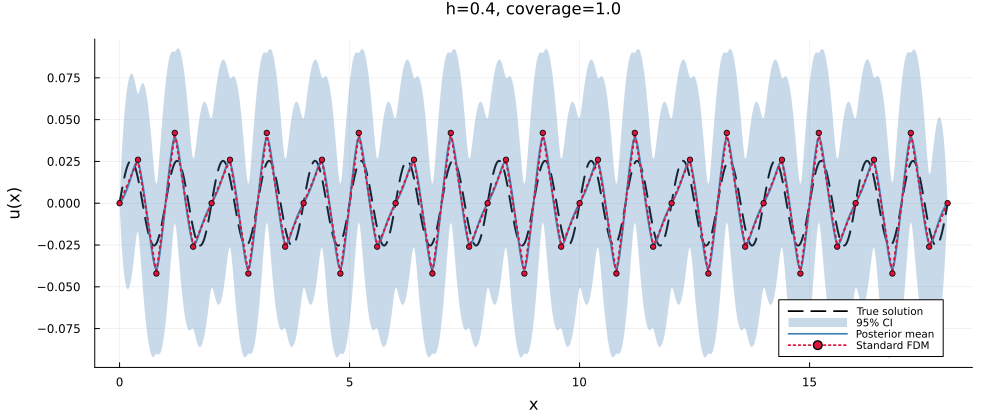

In [17]:
function run_pfdm(dt; ν, ℓ, σf, C, τ, n_test=1801)
    # --------------------------------------------------------
    # Training grid
    # --------------------------------------------------------
    x_train = collect(0.0:dt:18.0)
    n_train = length(x_train)

    H       = observation_matrix(n_train, dt)
    y_train = make_y_train(x_train)

    noise_var = C * dt^(2τ)
    Σ_diag = vcat(
        [0.0],
        fill(noise_var, n_train - 2),
        [0.0]
    )
    Σ = Diagonal(Σ_diag)

    K_train = kernel_matrix_matern(
        x_train, x_train;
        ν=ν, ℓ=ℓ, σf=σf
    )

    K_obs = Hermitian(
        H * K_train * H' +
        Σ +
        1e-10 * I
    )

    K_chol = cholesky(K_obs)

    # --------------------------------------------------------
    # Fine test grid
    # --------------------------------------------------------
    X_test = collect(
        range(0.0, 18.0, length=n_test)
    )

    K_test_train = kernel_matrix_matern(
        X_test, x_train;
        ν=ν, ℓ=ℓ, σf=σf
    )

    # Cross covariance with observations
    Ks = K_test_train * H'

    # Posterior mean
    μ_post = Ks * (K_chol \ y_train)

    # Posterior variance:
    # k(x*,x*) = σf^2 for stationary Matérn kernel
    W = K_chol.L \ Ks'

    var_post =
        σf^2 .-
        vec(sum(W.^2, dims=1))

    std_post =
        sqrt.(max.(var_post, 0.0))

    u_true =
        u_exact.(X_test)

    return X_test, μ_post, std_post, u_true
end


# ============================================================
# Fine-test-grid evaluation
# ============================================================

plots_list = []

println("\n=== Fine test-grid evaluation ===")

for dt in dt_list

    best_ℓ, best_σf, best_C =
        best_params[dt]

    X_test, μ, σ, u_true =
        run_pfdm(
            dt;
            ν=ν_fixed,
            ℓ=best_ℓ,
            σf=best_σf,
            C=best_C,
            τ=τ_fixed,
            n_test=1801
        )

    err =
        abs.(μ .- u_true)

    rmse =
        sqrt(mean((μ .- u_true).^2))

    linf =
        maximum(err)

    coverage =
        mean(
            err .<=
            1.96 .* σ
        )

    mean_halfwidth =
        mean(1.96 .* σ)

    println("----------------------------------------")
    @printf("h              = %.6g\n", dt)
    @printf("n_train        = %d\n", length(collect(0.0:dt:18.0)))
    @printf("n_test         = %d\n", length(X_test))
    @printf("ell            = %.6g\n", best_ℓ)
    @printf("sigma_f        = %.6g\n", best_σf)
    @printf("C_hat          = %.6g\n", best_C)
    @printf("RMSE           = %.6g\n", rmse)
    @printf("Linf           = %.6g\n", linf)
    @printf("coverage       = %.3f\n", coverage)
    @printf("mean 95%% width = %.6g\n", mean_halfwidth)

    p = plot(
        X_test, u_true;
        label="True solution",
        lw=2,
        ls=:dash,
        color=:black,
        xlabel="x",
        ylabel="u(x)",
        title="h=$(dt), coverage=$(round(coverage,digits=3))",
        titlefontsize=11,
        legendfontsize=7
    )

    plot!(
        p,
        X_test,
        μ .+ 1.96 .* σ;
        fillrange=μ .- 1.96 .* σ,
        fillalpha=0.3,
        linealpha=0,
        label="95% CI",
        color=:steelblue
    )

    plot!(
        p,
        X_test,
        μ;
        label="Posterior mean",
        lw=2,
        color=:steelblue
    )

    # FDM only exists on training points
    x_fdm, u_fdm =
        solve_fdm(dt)

    plot!(
        p,
        x_fdm,
        u_fdm;
        label="Standard FDM",
        lw=2,
        ls=:dot,
        color=:crimson,
        markershape=:circle,
        markersize=3
    )

    push!(
        plots_list,
        p
    )
end


fig = plot(
    plots_list...;
    layout=(length(dt_list),1),
    size=(1000, 420*length(dt_list)),
    margin=5Plots.mm
)

display(fig)

savefig(
    fig,
    "poisson_matern_finetest.png"
)

println("\nSaved: poisson_matern_finetest.png")


## 通常のFDM（比較用）

三重対角行列を直接解く標準的な有限差分法。各 h でのFDM解と最大誤差を求め，Probabilistic FDM と同じパネルに重ねてプロット。

## プロット（Probabilistic FDM ＋ 通常FDM 重ね描き）

In [11]:
# ============================================================
# 診断: C を coarsening defect で固定し、ℓ の LML だけ表示
# ============================================================

dt = dt_list[1]
x_all   = collect(0.0:dt:18.0)
n_total = length(x_all)
H       = observation_matrix(n_total, dt)
y_train = make_y_train(x_all)

_, u_fdm = solve_fdm(dt)
σf_fixed = sqrt(mean(u_fdm .^2))
C_hat, x_C, c_hat, defect = estimate_C_coarsening(dt; p=τ_fixed)

println("=== calibration diagnostics (h=$(dt)) ===")
println("σf_fixed = $(round(σf_fixed, sigdigits=6))")
println("C_hat    = $(round(C_hat, sigdigits=6))")
println("RMS(c_hat) = $(round(sqrt(mean(c_hat.^2)), sigdigits=6))")
println("number of defect points = $(length(c_hat))")

println("\n=== lml table: ℓ only ===")
@printf("%-14s %-16s\n", "ℓ", "log marginal")
println("-"^32)

best_lml = -Inf
best_l = ℓ_grid[1]

for ℓ in ℓ_grid
    lml = try
        log_marginal_matern(
            x_all, y_train;
            H=H, dt=dt, ν=ν_fixed,
            ℓ=ℓ, σf=σf_fixed, C=C_hat, τ=τ_fixed
        )
    catch
        NaN
    end

    @printf("%-14.6g %-16s\n",
        ℓ,
        isnan(lml) ? "NaN" : string(round(lml, digits=4))
    )

    if !isnan(lml) && lml > best_lml
        best_lml = lml
        best_l = ℓ
    end
end

println("-"^32)
println("Best: ℓ=$(round(best_l,sigdigits=6)), C_hat=$(round(C_hat,sigdigits=6)), σf=$(round(σf_fixed,sigdigits=6)), lml=$(round(best_lml,digits=4))")


=== calibration diagnostics (h=0.4) ===
σf_fixed = 0.0309286
C_hat    = 1.84387
RMS(c_hat) = 1.35789
number of defect points = 21

=== lml table: ℓ only ===
ℓ              log marginal    
--------------------------------
0.4            -44.6206        
0.5            -62.6406        
1              -148.8645       
2              -196.3106       
--------------------------------
Best: ℓ=0.4, C_hat=1.84387, σf=0.0309286, lml=-44.6206
